##Разговорные рекомендации музыки по пользовательскому интенту

__Цель__: Исследовать, какие семантические признаки музыкальных треков могут быть полезны для задач рекомендаций, и реализовать базовый пайплайн по автоматическому извлечению или предсказанию таких признаков.

__Как собирался датасет__: В качестве источника использована подвыборка стандартизированного открытого корпуса Free Music Archive, опубликованная на платформе Hugging Face: rpmon/fma-genre-classification. фрагменты треков длительностью по 30 секунд (mono, частота дискретизации 16 кГц). Выборка формировалась в потоковом режиме.

__Какие признаки были выбраны и почему__:
* CLAP эмбеддинги: Выбраны в качестве фундамента сходства, так как мультимодальное представление одновременно улавливает тембр, ритмический рисунок, гармонию и общую семантику звучания.
* Семантическое настроение (`mood_energetic`, `mood_calm`, `mood_sad`, `mood_happy`): Мягкие вероятности настроения. Выбраны для обеспечения эмоциональной однородности плейлистов, так как жанровые теги не отражают аффективный посыл трека.
* Контекст использования (`context_workout`, `context_focus`, `context_party`, `context_relaxation`): Вероятности применимости трека в жизненных сценариях. Выбраны для задач контекстно-зависимых рекомендаций, позволяя подбирать музыку под текущую активность пользователя.
* Акустические дескрипторы (`bpm`, `rms_energy`, `spectral_centroid`, `spectral_rolloff`): Физические характеристики аудиосигнала. Выбраны как детерминированные параметры для контроля динамики, громкости и частотного баланса сессии.

__Какие модели использовались для извлечения признаков__:
* `laion/clap-htsat-unfused`: Мультимодальная нейросетевая модель, применялась для:
  * Извлечения 512-мерных спроецированных аудио-эмбеддингов.
  * Zero-Shot классификации настроений и сценариев через сопоставление аудиовектора с текстовыми промптами с последующим применением функции Softmax.
* `librosa`: Использовалась для прямого алгоритмического извлечения темпоральных и частотных характеристик.

__Какие эксперименты были проведены__:
* Анализ распределений: Оценена представленность предсказанных категорий настроений и контекстов по 8 сбалансированным жанрам.
* Корреляционный анализ: Построена матрица корреляций Пирсона между низкоуровневыми DSP-дескрипторами и высокоуровневыми семантическими вероятностями.
* Проекция латентного пространства: Выполнено 2D-снижение размерности эмбеддингов с помощью t-SNE с сопоставлением кластеризации по жанрам против кластеризации по настроениям/контекстам.
* Моделирование сходства: Реализована функция поиска ближайших треков на основе косинусного расстояния в пространстве CLAP-векторов для треков разных жанров.

__Какие выводы можно сделать для задач музыкальных рекомендаций__:
* Аудио-эмбеддинги успешно преодолевают "жанровый пузырь", находя близкие по атмосфере и звуковому продакшну треки из смежных жанров.
* Признак `bpm` показал околонулевую корреляцию с эмоциональными и функциональными метками. Темп применим лишь как вторичный технический фильтр, но не основа поиска схожести.
* Наиболее оптимальная структура рекомендательного пайплайна - отбор кандидатов векторным поиском с последующей контекстной фильтрацией и ранжированием по скорам активности и уровню энергии.

__Какие ограничения и проблемы обнаружены__:
* Усреднение спектральных признаков и эмбеддинга по фиксированному 30-секундному фрагменту игнорирует композиционную динамику трека, например, переходы от тихого интро к тяжелому припеву.
* Извлечение признаков с помощью глубоких спектрограммных трансформеров требует значительных ресурсов GPU и малоприменимо для инференса без предварительного оффлайн-индексирования каталога.
* Модель анализирует исключительно акустический спектрограммный сигнал. Из-за этого эмоциональный смысл песни с грустным или агрессивным текстом, но положенным на мажорную и бодрую аранжировку, определяется как позитивный/танцевальный.

In [ ]:
import pandas as pd
import torch
import librosa
import numpy as np
import torch.nn.functional as F
from transformers import AutoProcessor, ClapModel
from datasets import load_dataset
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.manifold import TSNE
from sklearn.metrics.pairwise import cosine_similarity

__Необходимые библиотеки__

In [ ]:
dataset = load_dataset("rpmon/fma-genre-classification", split="train", streaming=True)

genres = ['Electronic', 'Experimental', 'Folk', 'Hip-Hop', 'Instrumental', 'International', 'Pop', 'Rock']
target_genre = 8
target_artist = 1

__Загрузка датасета и настройка параметров__
* `dataset` - потоковый датасет `rpmon/fma-genre-classification` (split=train). Датасет не содержит пропусков данных.
* `genres` - список названий музыкальных жанров (8 классов). Включены все имеющиеся в датасете классы.
* `target_genre` - ограничение: не более 8 треков на один жанр.
* `target_artist` - ограничение: не более 1 трека на одного артиста.

In [ ]:
genre_counts = {g: 0 for g in genres}
seen_artists = set()
collected = []

for item in dataset:
    genre = dataset.features["genre"].int2str(item["genre"])
    artist = item.get("artist")
    if genre in genre_counts and genre_counts[genre] < target_genre:
        if artist not in seen_artists:
            seen_artists.add(artist)
            genre_counts[genre] += 1
            arr = item["audio"]["array"]
            sr = item["audio"]["sampling_rate"]
            collected.append({"track_id": item.get("track_id"),
                              "title": item.get("title"),
                              "artist": artist,
                              "genre": genre,
                              "duration_sec": round(len(arr) / sr, 2),
                              "sampling_rate": sr,
                              "audio": arr,
                              "source": "HuggingFace (rpmon/fma-genre-classification)"})
    if all(i >= target_genre for i in genre_counts.values()):
        break

df_tracks = pd.DataFrame(collected)
print("Распределение по жанрам:")
print(df_tracks["genre"].value_counts())
print("Первые 5 записей датасета:")
display(df_tracks[["title", "artist", "genre", "duration_sec", "sampling_rate", "source"]].head())

Распределение по жанрам:
genre
Electronic       8
Pop              8
Rock             8
International    8
Folk             8
Hip-Hop          8
Instrumental     8
Experimental     8
Name: count, dtype: int64
Первые 5 записей датасета:


,title,artist,genre,duration_sec,sampling_rate,source
0,Intro To Horror,Dylan Palme,Electronic,29.98,16000,HuggingFace (rpmon/fma-genre-classification)
1,Lavender Hip Mob,Lee Rosevere,Pop,30.00,16000,HuggingFace (rpmon/fma-genre-classification)
2,Break It Now,Radio 421,Rock,30.00,16000,HuggingFace (rpmon/fma-genre-classification)
3,"Restaurant Concert, Song 2",Demiran Ćerimović and His Orkestar,International,29.99,16000,HuggingFace (rpmon/fma-genre-classification)
4,Celebration,Krebs,Rock,29.98,16000,HuggingFace (rpmon/fma-genre-classification)


__Источники данных__: Использована подвыборка стандартизированного открытого корпуса Free Music Archive, опубликованная на платформе Hugging Face: rpmon/fma-genre-classification. Датасет содержит фрагменты треков длительностью по 30 секунд (mono, частота дискретизации 16 кГц). Выборка формировалась в потоковом режиме, что позволило извлечь фрагменты без предварительной загрузки всего репозитория.

__Как отбирались треки__: Отбор производился итеративным проходом по потоку данных. При отборе каждого трека проверялось сколько треков этого жанра и исполнителя уже присутствует в отобранном множестве.

__Включённые жанры и категории__: В датасет вошли все 8 жанров исходного датасета 'Electronic', 'Experimental', 'Folk', 'Hip-Hop', 'Instrumental', 'International', 'Pop', 'Rock'. Этот набор жанров представляет различные, малоскоррелированные, направления музыки, поэтому набор не изменялся.

__Ограничения по количеству треков на жанр или артиста__: По жанрам: 8 треков на каждый жанр. Это предотвращает смещение будущих метрик сходства и кластеризации в сторону доминирующего класса. По артистам: 1 трек на 1 артиста. Это исключает ситуацию, когда модель выявляет сходство треков на основе персонального акустического почерка и мастеринга одного исполнителя.

###Формирование набора признаков

Определим набор семантических признаков, которыми можно обогатить музыкальные треки. Для обогащения датасета выбран гибридный подход: комбинация мультимодальной нейросетевой модели и автоматического анализа аудиосигнала.

__Низкоуровневые акустические дескрипторы__:
1. Beats Per Minute (librosa.beat.beat_track).
2. Среднеквадратичная амплитуда (librosa.feature.rms).
3. Центр масс спектра (librosa.feature.spectral_centroid).
4. Частотный спад (librosa.feature.spectral_rolloff).
- Зачем нужно: резкий скачок темпа вызывает отток слушателя, так как нарушает предсказуемость и плавность восприятия, а резкая смена ритма требует от слушателя перестройки внимания и может восприниматься как дискомфорт. Учет этих признаков позволяет ранжировать треки так, чтобы сохранялась динамика. К тому же эти признаки извлекаются напрямую из файла, то есть не требуется контекст, что является важным фактором, так как контекста может не быть или его долго обрабатывать.

__Семантические вероятностные признаки__:
1. Вероятности настроений energetic, calm, sad, happy, (Zero-shot классификация моделью CLAP).
2. Контекст использования workout, focus, party, relaxation, (Zero-shot классификация моделью CLAP).
- Зачем нужно: cлушатели часто ищут музыку под текущее психологическое состояние. Моделирование настроения в виде мягкого распределения вероятностей, позволяет отразить неоднозначность музыки, например, трек может быть одновременно меланхоличным и ритмичным. Происходит снижение ошибки жанровой классификации: жанр часто не отражает эмоциональный заряд. Предсказание пригодности трека для конкретного сценария позволяет собирать плейлисты, которые подстраиваются под ситуацию и плавно меняют динамику по ходу прослушивания.

__Семантические эмбеддинги__:
1. Проекция аудиосигнала (аудио-энкодер модели CLAP).
- Зачем нужно: многомерный плотный вектор отражает комплексную акустическую и семантическую картину, которую невозможно полностью формализовать набором дискретных категорий.


*Предобученная модель CLAP обучена на миллионах пар аудио-текстовое описание. Это позволяет получать интерпретируемые семантические теги без необходимости собирать размеченный обучающий датасет.*

In [ ]:
mood_labels = ["energetic", "calm", "sad", "happy"]
mood_prompts = ["energetic high-energy music with drive",
                "calm peaceful quiet relaxing acoustic melody",
                "sad melancholic depressing dark emotional song",
                "happy uplifting joyful cheerful upbeat music"]
context_labels = ["workout", "focus", "party", "relaxation"]
context_prompts = ["music for intense gym fitness workout and running",
                   "background music for studying concentration and deep focus",
                   "dance music for a night club party and celebration",
                   "soothing ambient music for sleep meditation and relaxation"]

* `mood_labels` - метки настроения.
* `mood_prompts` - текстовые промпты для zero-shot классификации по настроению; соответствуют `mood_labels` по индексу.
* `context_labels` - метки контекста.
* `context_prompts` - текстовые промпты для zero-shot классификации по контексту; соответствуют `context_labels` по индексу.

In [ ]:
processor = AutoProcessor.from_pretrained("laion/clap-htsat-unfused")
clap_model = ClapModel.from_pretrained("laion/clap-htsat-unfused")
clap_model.eval()

def extract_tensor(output):
    if hasattr(output, "pooler_output") and output.pooler_output is not None:
        return output.pooler_output
    elif hasattr(output, "last_hidden_state"):
        return output.last_hidden_state[:, 0, :]
    elif isinstance(output, (tuple, list)):
        return output[0]
    return output

with torch.no_grad():
    mood_inputs = processor(text=mood_prompts, return_tensors="pt", padding=True)
    mood_out = clap_model.get_text_features(**mood_inputs)
    mood_text_embeds = F.normalize(extract_tensor(mood_out), dim=-1)
    context_inputs = processor(text=context_prompts, return_tensors="pt", padding=True)
    context_out = clap_model.get_text_features(**context_inputs)
    context_text_embeds = F.normalize(extract_tensor(context_out), dim=-1)

extracted_features = []
audio_embeddings_list = []
for _, row in df_tracks.iterrows():
    y = librosa.resample(row["audio"].astype(np.float32), orig_sr=row["sampling_rate"], target_sr=48000)
    tempo, _ = librosa.beat.beat_track(y=y, sr=48000)
    bpm = float(np.atleast_1d(tempo)[0])
    rms = float(np.mean(librosa.feature.rms(y=y)))
    spec_cent = float(np.mean(librosa.feature.spectral_centroid(y=y, sr=48000)))
    spec_rolloff = float(np.mean(librosa.feature.spectral_rolloff(y=y, sr=48000)))

    inputs = processor(audio=y, sampling_rate=48000, return_tensors="pt")
    with torch.no_grad():
        a_out = clap_model.get_audio_features(**inputs)
        a_embed = F.normalize(extract_tensor(a_out), dim=-1)
        audio_embeddings_list.append(a_embed.numpy()[0])
        m_probs = F.softmax(torch.matmul(a_embed, mood_text_embeds.T) * 10.0, dim=-1).numpy()[0]
        c_probs = F.softmax(torch.matmul(a_embed, context_text_embeds.T) * 10.0, dim=-1).numpy()[0]

    feat = {"track_id": row["track_id"],
            "title": row["title"],
            "artist": row["artist"],
            "genre": row["genre"],
            "bpm": round(bpm, 2),
            "rms_energy": round(rms, 4),
            "spectral_centroid": round(spec_cent, 2),
            "spectral_rolloff": round(spec_rolloff, 2)}
    for l, p in zip(mood_labels, m_probs):
        feat[f"mood_{l}"] = round(float(p), 4)
    for l, p in zip(context_labels, c_probs):
        feat[f"context_{l}"] = round(float(p), 4)

    feat["dominant_mood"] = mood_labels[int(np.argmax(m_probs))]
    feat["dominant_context"] = context_labels[int(np.argmax(c_probs))]
    extracted_features.append(feat)

df_enriched = pd.DataFrame(extracted_features)
embeddings_array = np.array(audio_embeddings_list)
display(df_enriched.head(5))

Loading weights:   0%|          | 0/447 [00:00<?, ?it/s]

,track_id,title,artist,genre,bpm,rms_energy,spectral_centroid,spectral_rolloff,mood_energetic,mood_calm,mood_sad,mood_happy,context_workout,context_focus,context_party,context_relaxation,dominant_mood,dominant_context
0,55183,Intro To Horror,Dylan Palme,Electronic,125.00,0.0686,2504.47,5142.65,0.2763,0.0618,0.1453,0.5167,0.2353,0.1243,0.5813,0.0591,happy,party
1,120184,Lavender Hip Mob,Lee Rosevere,Pop,100.45,0.1720,1541.38,3290.32,0.2433,0.0477,0.0922,0.6167,0.3640,0.2154,0.3469,0.0737,happy,workout
2,85816,Break It Now,Radio 421,Rock,122.28,0.2421,1787.38,3878.60,0.5492,0.0151,0.1241,0.3116,0.3258,0.0844,0.5502,0.0397,energetic,party
3,36277,"Restaurant Concert, Song 2",Demiran Ćerimović and His Orkestar,International,170.45,0.1370,1539.56,3147.64,0.1316,0.1150,0.3074,0.4461,0.3232,0.1456,0.5061,0.0251,happy,party
4,56552,Celebration,Krebs,Rock,165.44,0.3581,2233.05,4547.35,0.4528,0.0148,0.1627,0.3697,0.3033,0.0740,0.5898,0.0329,energetic,party


__Описание используемых моделей__: Библиотеки и модели:
  - laion/clap-htsat-unfused: Использована для извлечения плотных представлений и zero-shot классификации.
  - librosa: Использована для вычисления детерминированных спектрально-временных признаков.

__Обоснование выбора__: Мультимодальный Zero-Shot подход снимает необходимость иметь размеченный датасет под каждую задачу: достаточно сформулировать текстовые описания настроения и контекста. Векторы CLAP содержат высокоуровневую семантику, тогда как DSP-дескрипторы дают физическую интерпретацию динамики трека.

__Рассмотренные альтернативы__: OpenAI Whisper: фокусируется на транскрибации речи, плохо кодирует музыку. Mert и Audio Spectrogram Transformer нужно сначала дообучить на размеченных примерах - у них для этого есть отдельные классификационные головы. А CLAP умеет предсказывать классы сразу, без дообучения. LLM: Не решает задачу анализа незнакомых треков, так как LLM не имеет прямого доступа к аудиопотоку.

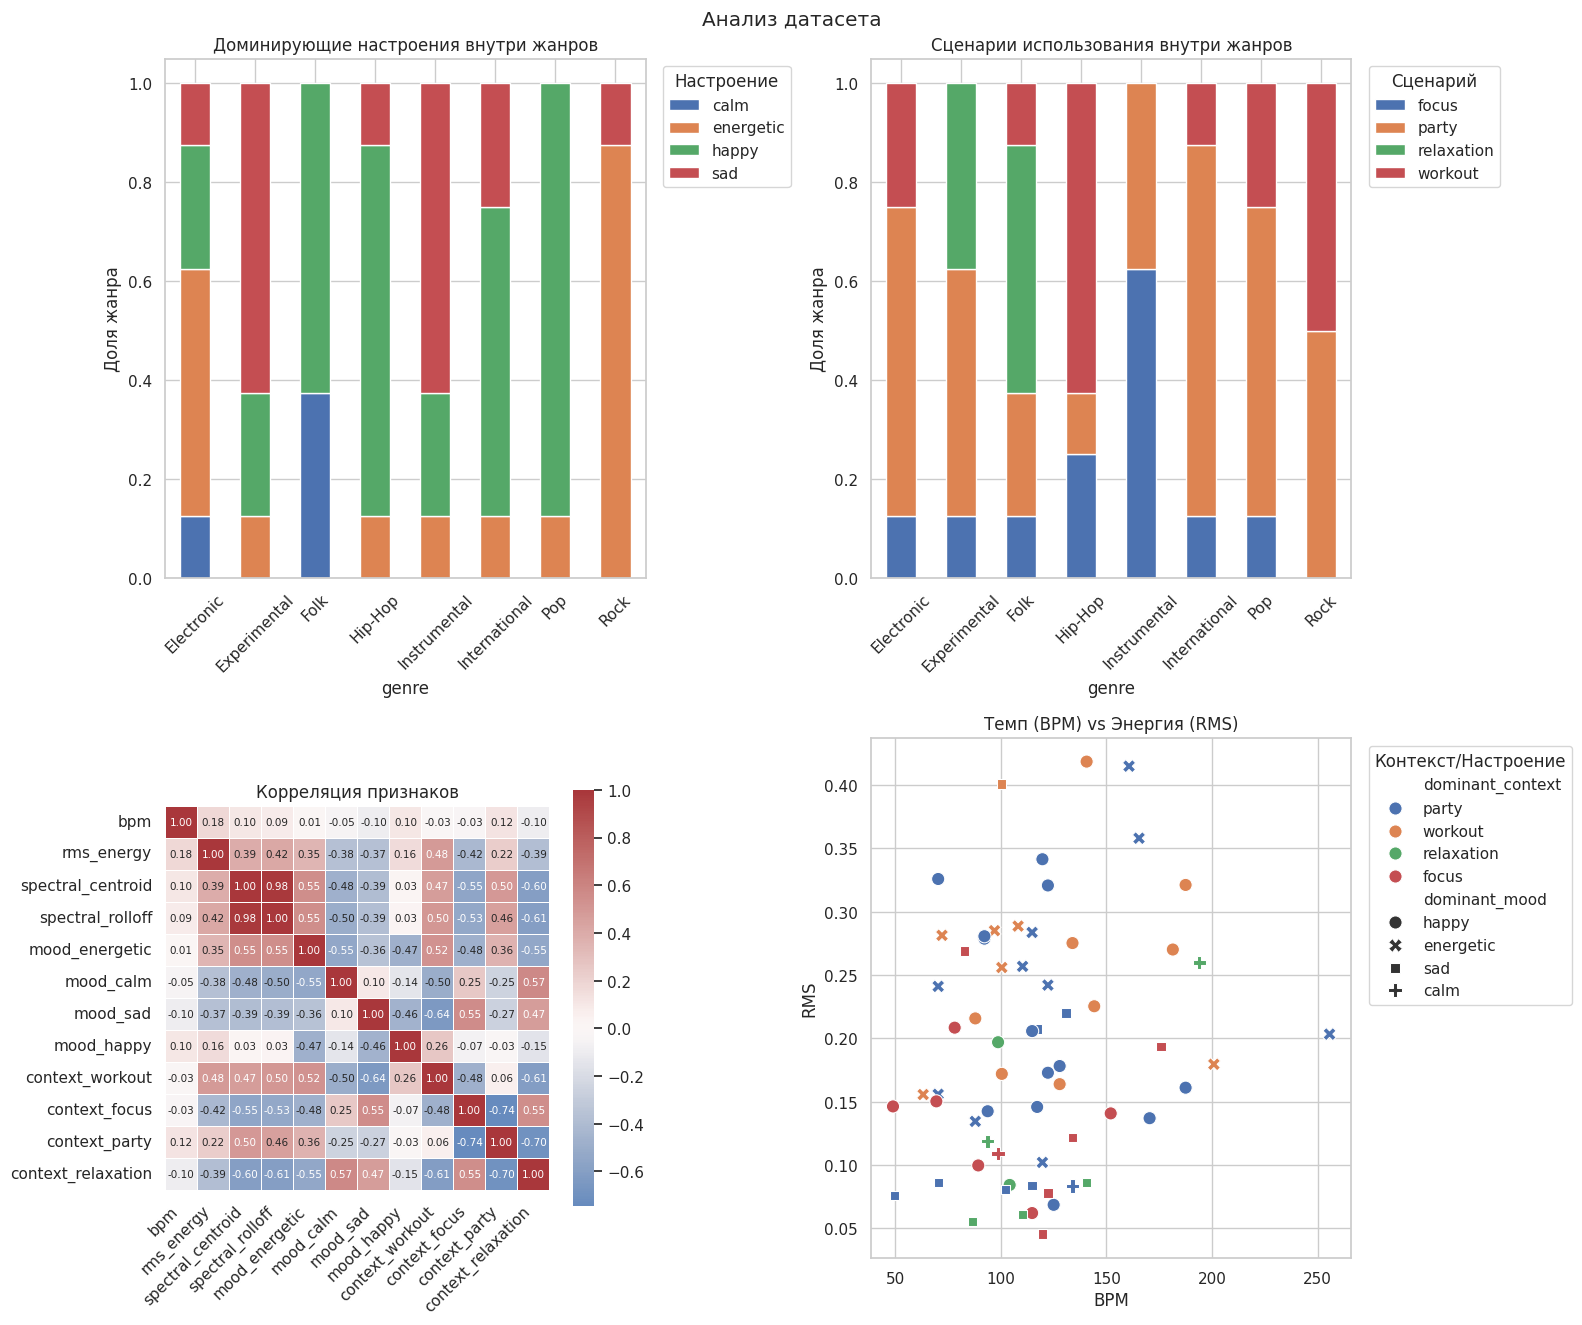

In [ ]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(16, 14))
fig.suptitle("Анализ датасета")

mood_genre = pd.crosstab(df_enriched["genre"], df_enriched["dominant_mood"], normalize="index")
mood_genre.plot(kind="bar", stacked=True, ax=axes[0, 0])
axes[0, 0].set_title("Доминирующие настроения внутри жанров")
axes[0, 0].set_ylabel("Доля жанра")
axes[0, 0].tick_params(axis="x", rotation=45)
axes[0, 0].legend(title="Настроение", bbox_to_anchor=(1.02, 1), loc="upper left")

ctx_genre = pd.crosstab(df_enriched["genre"], df_enriched["dominant_context"], normalize="index")
ctx_genre.plot(kind="bar", stacked=True, ax=axes[0, 1])
axes[0, 1].set_title("Сценарии использования внутри жанров")
axes[0, 1].set_ylabel("Доля жанра")
axes[0, 1].tick_params(axis="x", rotation=45)
axes[0, 1].legend(title="Сценарий", bbox_to_anchor=(1.02, 1), loc="upper left")

cols_for_corr = ["bpm", "rms_energy", "spectral_centroid", "spectral_rolloff", "mood_energetic", "mood_calm", "mood_sad", "mood_happy", "context_workout", "context_focus", "context_party", "context_relaxation"]
corr_matrix = df_enriched[cols_for_corr].corr()

axes[1, 0].grid(False)
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="vlag", center=0, square=True, linewidths=0.5, annot_kws={"size": 7.5}, cbar_kws={"shrink": 0.8}, ax=axes[1, 0])
axes[1, 0].set_title("Корреляция признаков")
axes[1, 0].tick_params(axis="x", rotation=45)
axes[1, 0].set_xticklabels(axes[1, 0].get_xticklabels(), rotation=45, ha="right")

sns.scatterplot(data=df_enriched, x="bpm", y="rms_energy", hue="dominant_context", style="dominant_mood", s=90, ax=axes[1, 1])
axes[1, 1].set_title("Темп (BPM) vs Энергия (RMS)")
axes[1, 1].set_xlabel("BPM")
axes[1, 1].set_ylabel("RMS")
axes[1, 1].legend(bbox_to_anchor=(1.02, 1), loc="upper left", title="Контекст/Настроение")

plt.tight_layout(rect=[0, 0, 1, 1])
plt.show()

In [ ]:
print("Распределение доминирующих настроений:")
print(df_enriched["dominant_mood"].value_counts(normalize=True).apply(lambda x: f"{x*100:.1f}%"))
print("Распределение доминирующих сценариев:")
print(df_enriched["dominant_context"].value_counts(normalize=True).apply(lambda x: f"{x*100:.1f}%"))

Распределение доминирующих настроений:
dominant_mood
happy        45.3%
energetic    25.0%
sad          23.4%
calm          6.2%
Name: proportion, dtype: object
Распределение доминирующих сценариев:
dominant_context
party         46.9%
workout       23.4%
focus         18.8%
relaxation    10.9%
Name: proportion, dtype: object


__Анализ доминирующих настроений и сценариев использования внутри жанров__:
* Жанр слабо показывает настроение. В одном жанре могут быть написаны песни противоположные по настроению. К тому же некоторые жанры содержат почти равномерное распределение настроений.
* Аналогичная ситуация со сценариями использования.  

__Анализ матрицы корреляций Пирсона__:
* `spectral_centroid` и `spectral_rolloff` имеют близкую к единице корреляцию, что согласуется с физикой звука (смещение спектрального центра вверх закономерно поднимает границу высокочастотного спада).
* Энергия сигнала `rms_energy` положительно коррелирует со `spectral_centroid` (0.39), `spectral_rolloff`: (0.42), а также с контекстом тренировок `context_workout` (0.48).
* Сильная отрицательная корреляция между эмоциональными антиподами: `mood_energetic` и `mood_calm` (-0.55), `context_workout` и `context_relaxation` (-0.61), `context_party` и `context_focus` (-0.74).
* `context_relaxation` имеет устойчивую отрицательную связь со спектральными характеристиками `spectral_rolloff` (-0.61), `spectral_centroid` (-0.60), что подтверждает: для релаксации модель выбирает треки без резких высоких частот.
* Темп показал слабую линейную корреляцию со всеми семантическими признаками. Можно сдеелать вывод, что BPM без учета аранжировки и плотности звука слабо информативен для определения эмоционального посыла композиции.

__Анализ BPM vs RMS__:
* Высокоэнергетический кластер cформирован в основном треками с настроением `energetic` и сценариями `workout` / `party`.
* Низкоэнергетический кластер концентрирует треки сценариев `focus` и `relaxation` с преобладанием настроений `sad` и `calm`. Для этих композиций характерен более широкий динамический диапазон.


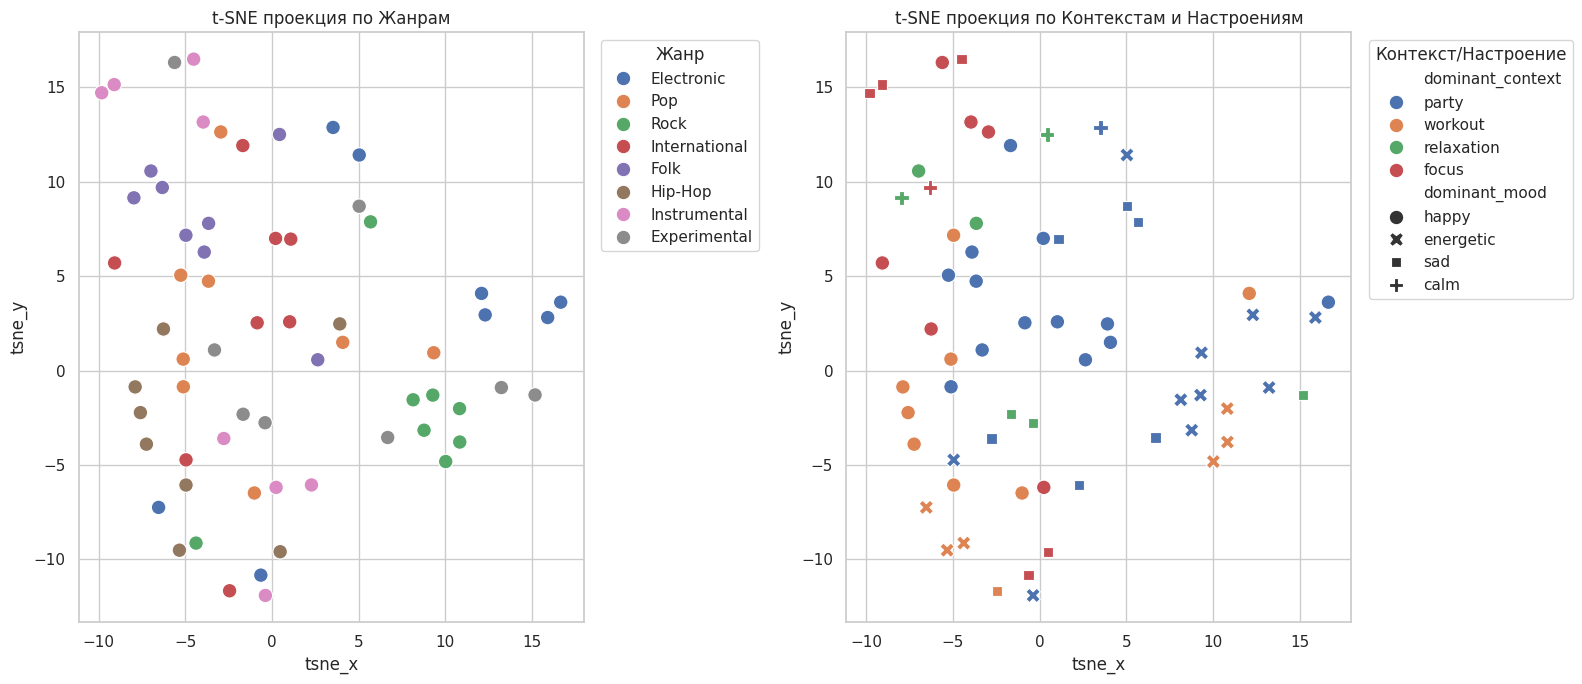

In [ ]:
tsne = TSNE(n_components=2, perplexity=12, random_state=11)
embeddings_2d = tsne.fit_transform(embeddings_array)
df_enriched["tsne_x"] = embeddings_2d[:, 0]
df_enriched["tsne_y"] = embeddings_2d[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

sns.scatterplot(data=df_enriched, x="tsne_x", y="tsne_y", hue="genre",  s=110, ax=axes[0])
axes[0].set_title("t-SNE проекция по Жанрам")
axes[0].legend(bbox_to_anchor=(1.02, 1), loc="upper left", title="Жанр")

sns.scatterplot(data=df_enriched, x="tsne_x", y="tsne_y", hue="dominant_context", style="dominant_mood", s=110, ax=axes[1])
axes[1].set_title("t-SNE проекция по Контекстам и Настроениям")
axes[1].legend(bbox_to_anchor=(1.02, 1), loc="upper left", title="Контекст/Настроение")

plt.tight_layout()
plt.show()

__Анализ проекции по контекстам и настроениям__: высокоэнергетичные треки energetic/workout/party сгруппированы в правой нижней и центральной зонах, в то время как спокойные композиции focus/relaxation/sad/calm сконцентрированы в левом верхнем секторе.

In [ ]:
similarity_matrix = cosine_similarity(embeddings_array)
def get_recommendations(query_idx, top_k=3):
    sim_scores = similarity_matrix[query_idx].copy()
    sim_scores[query_idx] = -1.0
    top_indices = np.argsort(sim_scores)[::-1][:top_k]

    query = df_enriched.iloc[query_idx]
    print(f"Целевой трек [{query_idx}]: \"{query['title']}\" — {query['artist']}")
    print(f"Жанр: {query['genre']} | Mood: {query['dominant_mood']} | Context: {query['dominant_context']}")

    results = []
    for rank, idx in enumerate(top_indices, 1):
        rec = df_enriched.iloc[idx]
        results.append({
            "Rank": rank,
            "Similarity": round(float(sim_scores[idx]), 4),
            "Title": rec["title"],
            "Artist": rec["artist"],
            "Genre": rec["genre"],
            "BPM": rec["bpm"],
            "Mood": rec["dominant_mood"],
            "Context": rec["dominant_context"]
        })
    display(pd.DataFrame(results))
    print()

selected_genres = set()
demo_indices = []
for idx, g in enumerate(df_enriched["genre"]):
    if g not in selected_genres and len(demo_indices) < 4:
        selected_genres.add(g)
        demo_indices.append(idx)

for q_id in demo_indices:
    get_recommendations(q_id, top_k=3)

Целевой трек [0]: "Intro To Horror" — Dylan Palme
Жанр: Electronic | Mood: happy | Context: party


,Rank,Similarity,Title,Artist,Genre,BPM,Mood,Context
0,1,0.6913,M0NOR4V3N,XC3N,Electronic,70.31,energetic,party
1,2,0.6104,foolsgame,The Carnys,Pop,255.68,energetic,party
2,3,0.5877,KING NeLSON,Alaclair Ensemble,Hip-Hop,187.50,happy,workout



Целевой трек [1]: "Lavender Hip Mob" — Lee Rosevere
Жанр: Pop | Mood: happy | Context: workout


,Rank,Similarity,Title,Artist,Genre,BPM,Mood,Context
0,1,0.8288,Just Fine,No Lala,Pop,122.28,happy,party
1,2,0.7928,Pulso (Por Stray),Pulso,Hip-Hop,78.12,happy,focus
2,3,0.7912,human nature is nature nature,FortyOne,Experimental,122.28,happy,party



Целевой трек [2]: "Break It Now" — Radio 421
Жанр: Rock | Mood: energetic | Context: party


,Rank,Similarity,Title,Artist,Genre,BPM,Mood,Context
0,1,0.9223,Celebration,Krebs,Rock,165.44,energetic,party
1,2,0.8874,Sleep Walk,Ylajali,Rock,70.31,energetic,party
2,3,0.8871,Toggle,Black Elk,Rock,96.98,energetic,workout



Целевой трек [3]: "Restaurant Concert, Song 2" — Demiran Ćerimović and His Orkestar
Жанр: International | Mood: happy | Context: party


,Rank,Similarity,Title,Artist,Genre,BPM,Mood,Context
0,1,0.7572,Demmadont,Papascandy,International,92.21,happy,party
1,2,0.7213,Music For Baby,Radioactive Sparrow,Pop,92.21,happy,party
2,3,0.7045,A Quiet Lousy Roar,Big Blood,Folk,93.75,happy,party


__Насколько полученные признаки отражают реальную похожесть музыки__: Модель подбирает треки с близким эмоциональным окрасом и сценарием прослушивания.   Для рок-композиции Break It Now все три рекомендации сформированы треками жанра Rock с идентичным настроением energetic и высокими коэффициентами сходства.   Для трека Restaurant Concert, Song 2 ближайшим соседом стал трек того же направления, а на 2 и 3 местах оказались композиции совпавшие по контексту и настроению. В случае трека Lavender Hip Mob модель нашла стилистически близкие композиции из смежных жанров, при этом все найденные треки сохранили тональность happy. Это говорит о том что модель ориентируется на звучание, а не на формальный тег жанра.

__Наиболее полезные признаки__:
1. Эмбеддинги. Так как обладают стабильностью в выдаче рекомендаций: когда подавался целевой трек в модель сходства, эмбеддинги находили композиции, совпадающие по настроению и сценарию, даже если это треки из разных жанров. На графике t-SNE векторы не перемешались случайным образом, а образовали логичные смысловые скопления.   
2. Контекст и Настроение. В таблице рекомендаций для рок-трека Break It Now все три предложенных трека имеют высокое сходство метки energetic и party/workout. На матрице корреляций эти признаки показали сильную антикорреляцию для противоположных сущностей - это подтверждает, что признаки информативны, ортогональны и разделяют музыкальные сценарии.

__Наименее полезные признаки__:
1. BPM. На тепловой карте строка bpm практически пустая. Это значит, что сам по себе темп ничего не говорит о настроении трека или его сценарии.